# Data Audit

Before building the models, we first need to understand the data we are working with. 
In this notebook we explore the datasets to identify missing values, duplicates, inconsistencies, and unusual patterns that could affect our predictions. We also look at the target variables and the time-related features to spot potential data leakage. The goal is to understand what needs to be cleaned or adjusted before moving on to preprocessing and modelling.

## 1. Importing and Loading Data

In [7]:
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import matplotlib as mpl
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

# Plot settings
BLUE = "#5EDDF3"
ORANGE = "#F78441"
GRAY = "#8E9196"

mpl.rcParams["figure.dpi"] = 110
mpl.rcParams["axes.spines.top"] = False
mpl.rcParams["axes.spines.right"] = False
mpl.rcParams["font.size"] = 10.5

In [8]:
from pathlib import Path

# Project paths
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_PATH = PROJECT_ROOT / "data" / "raw"

# Load datasets
train = pd.read_csv(RAW_PATH / "train.csv")
test = pd.read_csv(RAW_PATH / "test.csv")
customers = pd.read_csv(RAW_PATH / "clientes.csv")
sample_submission = pd.read_csv(RAW_PATH / "sample_submission.csv")

# Dimensions
print("Train:", train.shape)
print("Test:", test.shape)
print("Customers:", customers.shape)
print("Sample submission:", sample_submission.shape)

# Training data
display(train.head())

Train: (6534, 40)
Test: (986, 38)
Customers: (1143, 13)
Sample submission: (986, 2)


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,spend_next_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,359.04,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,592.71,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,423.72,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,NaN,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,455.73,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


## 2. First Look at the Dataset

In [ ]:
train.columns

Index(['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'repeat_purchase_90d', 'spend_next_90d',
       'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days',
       'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'customer_id', 'payment_type', 'salesperson', 'commercial_zone',
       'transport_method', 'warehouse', 'document_series', 'purchase_date', 'ID', 'random_noise'],
      dtype='str')

In [10]:
# Display all variables and their data types
display(pd.DataFrame({
    "Column": train.columns,
    "Data Type": train.dtypes.values,
    "Non-Null": train.notna().sum().values,
    "Missing": train.isna().sum().values
}).reset_index(drop=True))

,Column,Data Type,Non-Null,Missing
0,Total a Pagar,float64,6469,65
1,Total Bruto,float64,6469,65
2,Total Liquido,float64,6469,65
3,Total Imp_,float64,6469,65
4,Total Portes,float64,6469,65
5,Total Desc_ Global,float64,6469,65
6,Total Desc_ Linha,float64,6469,65
7,Custo,float64,6469,65
8,N_ Detalhes,float64,6469,65
9,invoice_count_current_purchase,float64,6469,65


Overall, the variables appear to have appropriate data types, with the exception of `purchase_date`, which is stored as text and should be converted to datetime.

## 3. Converting Data Types 

In [11]:
# Metric features
metric_features = [
    'Total a Pagar', 'Total Bruto', 'Total Liquido',
    'Total Imp_', 'Total Portes', 'Total Desc_ Global',
    'Total Desc_ Linha', 'Custo', 'N_ Detalhes',
    'invoice_count_current_purchase',
    'days_since_previous_purchase', 'customer_tenure_days',
    'prior_purchase_count', 'prior_total_spend',
    'prior_mean_purchase_value', 'prior_std_purchase_value',
    'prior_min_purchase_value', 'prior_max_purchase_value',
    'prior_mean_gap_days', 'prior_std_gap_days',
    'purchase_count_30d', 'spend_30d',
    'purchase_count_90d', 'spend_90d',
    'purchase_count_180d', 'spend_180d',
    'purchase_count_365d', 'spend_365d',
    'random_noise'
]

# Non-metric features
non_metric_features = [
    'payment_type', 'salesperson', 'commercial_zone',
    'transport_method', 'warehouse', 'document_series'
]

# Datetime features
datetime_features = ['purchase_date']

# Unique identifiers
id_features = ['ID', 'customer_id']

# Target variables
target_features = ['repeat_purchase_90d', 'spend_next_90d']

In [12]:
# Convert datetime features
train[datetime_features] = train[datetime_features].apply(
    pd.to_datetime, errors='coerce', format='%Y-%m-%d'
)

In [13]:
# General statistics of the metric features
train[metric_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,9.255563e+02,1.334998e+03,0.930000,188.920000,476.740000,1087.670000,2.229721e+04
Total Bruto,6469.0,8.861527e+02,1.327641e+03,0.830000,175.740000,445.740000,1036.700000,2.157828e+04
Total Liquido,6469.0,7.733364e+02,1.136356e+03,0.760000,154.380000,389.910000,903.370000,1.812781e+04
Total Imp_,6469.0,1.522199e+02,2.252624e+02,0.000000,29.930000,79.740000,184.840000,4.169400e+03
Total Portes,6469.0,1.151427e+00,5.844091e+00,0.000000,0.000000,0.000000,0.000000,1.810600e+02
Total Desc_ Global,6469.0,3.499072e-01,5.116564e+00,0.000000,0.000000,0.000000,0.000000,2.184900e+02
Total Desc_ Linha,6469.0,1.124664e+02,2.899863e+02,0.000000,0.000000,13.130000,92.280000,4.103440e+03
Custo,6469.0,3.281650e+02,5.195072e+02,0.000000,49.050000,152.540000,396.061499,7.427401e+03
N_ Detalhes,6469.0,2.152450e+01,2.771342e+01,1.000000,4.000000,11.000000,29.000000,4.230000e+02
invoice_count_current_purchase,6469.0,1.066007e+00,3.108069e-01,1.000000,1.000000,1.000000,1.000000,5.000000e+00


In [14]:
# General statistics of the non-metric variables
train.describe(include = ['O']).T

,count,unique,top,freq
payment_type,6274,9,Maybe Tomorrow Payment 7,4565
salesperson,6275,9,VLOOKUP Master 1,4054
commercial_zone,6469,5,Decorative Dashboard Zone 4,6260
transport_method,6273,80,Maybe Tomorrow Delivery 72,1119
warehouse,6274,2,Final Excel Warehouse 1,6253
document_series,6469,3,Ctrl Z Series 2,2738


## 4. Checking for Duplicates

In [15]:
#Check full rows of duplicated data
train.duplicated().sum()

np.int64(0)

In [16]:
# Check for duplicated IDs
train["ID"].duplicated().sum()

np.int64(0)

No fully duplicated rows or duplicated transaction IDs were found in the training dataset.

## 5. Checking for Missing Values

### 5.1. Quantitative Variables

In [17]:
# Check the percentage of missing values for each column:
round(train.isna().sum()/len(train)*100,2)

Total a Pagar                      0.99
Total Bruto                        0.99
Total Liquido                      0.99
Total Imp_                         0.99
Total Portes                       0.99
Total Desc_ Global                 0.99
Total Desc_ Linha                  0.99
Custo                              0.99
N_ Detalhes                        0.99
invoice_count_current_purchase     0.99
repeat_purchase_90d                0.00
spend_next_90d                    47.58
days_since_previous_purchase      13.18
customer_tenure_days               0.99
prior_purchase_count               0.99
prior_total_spend                  0.99
prior_mean_purchase_value         13.19
prior_std_purchase_value          17.03
prior_min_purchase_value          10.22
prior_max_purchase_value          10.22
prior_mean_gap_days               20.02
prior_std_gap_days                22.62
purchase_count_30d                 0.99
spend_30d                          0.99
purchase_count_90d                 0.99


In [ ]:
# Check number of missing values for each column
train.isna().sum()

Total a Pagar                       65
Total Bruto                         65
Total Liquido                       65
Total Imp_                          65
Total Portes                        65
Total Desc_ Global                  65
Total Desc_ Linha                   65
Custo                               65
N_ Detalhes                         65
invoice_count_current_purchase      65
repeat_purchase_90d                  0
spend_next_90d                    3109
days_since_previous_purchase       861
customer_tenure_days                65
prior_purchase_count                65
prior_total_spend                   65
prior_mean_purchase_value          862
prior_std_purchase_value          1113
prior_min_purchase_value           668
prior_max_purchase_value           668
prior_mean_gap_days               1308
prior_std_gap_days                1478
purchase_count_30d                  65
spend_30d                           65
purchase_count_90d                  65
spend_90d                

Several variables share the same number of missing values (65 or 0.99%), suggesting a possible common pattern (which will be analyzed in 4.3.). 

The regression target, `spend_next_90d`, has the highest percentage of missing values (47.58%), which could be related to customers who did not purchase again.

These patterns will be investigated further before deciding how to handle missing values.

### 5.2. Qualitative Variables

In [18]:
# Check the categories of the qualitative variables:
for col in non_metric_features:
    print(f"\n--- {col} ---")
    print(train[col].value_counts(dropna=False).to_string())


--- payment_type ---
payment_type
Maybe Tomorrow Payment 7     4565
Maybe Tomorrow Payment 12     991
Maybe Tomorrow Payment 9      502
NaN                           260
Maybe Tomorrow Payment 10     134
Maybe Tomorrow Payment 8       40
Maybe Tomorrow Payment 2       21
Maybe Tomorrow Payment 4        9
Maybe Tomorrow Payment 11       8
Maybe Tomorrow Payment 3        4

--- salesperson ---
salesperson
VLOOKUP Master 1    4054
VLOOKUP Master 4    1461
VLOOKUP Master 9     384
NaN                  259
VLOOKUP Master 7     201
VLOOKUP Master 2     123
VLOOKUP Master 3      30
VLOOKUP Master 6      12
VLOOKUP Master 5       7
VLOOKUP Master 8       3

--- commercial_zone ---
commercial_zone
Decorative Dashboard Zone 4    6260
Decorative Dashboard Zone 2     151
NaN                              65
Decorative Dashboard Zone 3      56
Decorative Dashboard Zone 6       1
Decorative Dashboard Zone 7       1

--- transport_method ---
transport_method
Maybe Tomorrow Delivery 72    1119
Maybe T

Some qualitative variables are dominated by one category, while `transport_method` has many different categories. All variables have some missing values, but the category names appear consistent, with no obvious spelling or formatting issues. Therefore, no category hygiene seems necessary at this stage.

### 5.3. Deeper Exploration into Missingness

After identifying the missing values, we will take a closer look at their patterns and possible causes. To investigate it we used **Chi-square tests of independence** and **bias-corrected Cramér's V** between missingness indicators and observed predictors. The Chi-square test assesses statistical association, while Cramér's V measures its strength. P-values were adjusted for multiple comparisons using the Benjamini–Hochberg method.

This analysis helps identify whether missingness is associated with observed characteristics, providing evidence against the Missing Completely at Random (MCAR) assumption.

In [43]:

from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

def cramers_v(table):
    """Bias-corrected Cramér's V."""
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    r, k = table.shape

    if n <= 1 or min(r, k) < 2:
        return np.nan

    phi2 = chi2 / n
    phi2_corr = max(0, phi2 - (k-1)*(r-1)/(n-1))
    r_corr = r - (r-1)**2/(n-1)
    k_corr = k - (k-1)**2/(n-1)

    denominator = min(k_corr-1, r_corr-1)
    return np.sqrt(phi2_corr / denominator) if denominator > 0 else 0.0


def test_missingness(df, target_col, predictors):
    missing = df[target_col].isna()
    results = []

    if missing.nunique() < 2:
        return pd.DataFrame()

    for col in predictors:
        if col == target_col:
            continue

        x = df[col].copy()

        # Numerical variables: quantile-based discretization
        if pd.api.types.is_numeric_dtype(x) and x.nunique() > 10:
            x = pd.qcut(x, q=5, duplicates="drop")

        # Exclude missing predictor values
        valid = x.notna()
        table = pd.crosstab(missing[valid], x[valid])

        if min(table.shape) < 2:
            continue

        chi2, p, _, expected = chi2_contingency(table)

        results.append({
            "predictor": col,
            "cramers_v": cramers_v(table),
            "p_value": p,
            "n": int(valid.sum()),
            "min_expected": expected.min()
        })

    result = pd.DataFrame(results)

    if result.empty:
        return result

    result["p_adjusted"] = multipletests(
        result["p_value"], method="fdr_bh"
    )[1]

    result["significant"] = result["p_adjusted"] < 0.05

    return result.sort_values(
        "cramers_v", ascending=False
    ).reset_index(drop=True)


In [45]:
candidate_predictors = [
    "prior_purchase_count",
    "customer_tenure_days",
    "commercial_zone",
    "payment_type",
    "warehouse",
    "transport_method",
    "purchase_count_90d"
]

raw_missing_cols = [
    c for c in train.columns
    if train[c].isna().any()
]

first_pass_results = {}

for col in raw_missing_cols:
    preds = [p for p in candidate_predictors if p != col]

    first_pass_results[col] = test_missingness(
        train, col, preds
    )

    print(f"=== {col} (n missing = {train[col].isna().sum()}) ===")
    print(first_pass_results[col])
    print()

=== Total a Pagar (n missing = 65) ===
Empty DataFrame
Columns: []
Index: []

=== Total Bruto (n missing = 65) ===
Empty DataFrame
Columns: []
Index: []

=== Total Liquido (n missing = 65) ===
Empty DataFrame
Columns: []
Index: []

=== Total Imp_ (n missing = 65) ===
Empty DataFrame
Columns: []
Index: []

=== Total Portes (n missing = 65) ===
Empty DataFrame
Columns: []
Index: []

=== Total Desc_ Global (n missing = 65) ===
Empty DataFrame
Columns: []
Index: []

=== Total Desc_ Linha (n missing = 65) ===
Empty DataFrame
Columns: []
Index: []

=== Custo (n missing = 65) ===
Empty DataFrame
Columns: []
Index: []

=== N_ Detalhes (n missing = 65) ===
Empty DataFrame
Columns: []
Index: []

=== invoice_count_current_purchase (n missing = 65) ===
Empty DataFrame
Columns: []
Index: []

=== spend_next_90d (n missing = 3109) ===
              predictor  cramers_v        p_value     n  min_expected     p_adjusted  significant
0    purchase_count_90d   0.356864  5.002507e-180  6469    370.324316 

- **Strong associations with purchase history:** Missingness in historical features is strongly associated with `prior_purchase_count` and `customer_tenure_days`. The strongest associations were observed for `prior_std_gap_days` (V = 0.9998), `prior_std_purchase_value` (V = 0.8314), and `prior_mean_gap_days` (V = 0.7570).

- **Target variable missingness:** `spend_next_90d` has 3109 missing values, with notable associations with `purchase_count_90d` (V = 0.357) and `prior_purchase_count` (V = 0.342). So, target missingness is associated with observed purchasing behaviour rather than being entirely random.

- **Shared missingness patterns:** Several variables, including invoice totals, purchase counts, and purchase dates, contain exactly 65 missing values and returned empty test results. The available observations lack sufficient variation to evaluate these associations, consistent with previously identified shared missingness patterns.

- **Weak associations in other variables:** `spend_365d`, `salesperson`, and `transport_method` showed no statistically significant associations with the selected predictors after p-value adjustment. For `payment_type` and `warehouse`, some statistically significant associations were detected, but their effect sizes were very small (V = 0.066 and V = 0.087, respectively).

- **Statistical limitations:** Several tests produced expected frequencies below 5, making their Chi-square p-values potentially unreliable. These associations should therefore be interpreted cautiously.

Therefore, the missingness is not entirely random, particularly in historical purchasing features and the target variable. Much of the missingness appears consistent with structural dependencies on purchase history. However, these tests cannot definitively distinguish between Missing at Random (MAR) and Missing Not at Random (MNAR).

## 6. Class balance and base rate

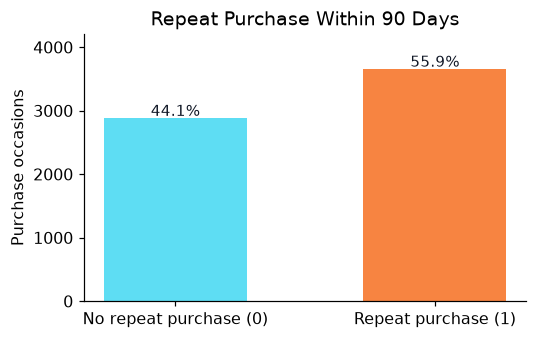

{0: 2880, 1: 3654}


In [21]:
counts = train["repeat_purchase_90d"].value_counts().sort_index()
pct = (counts / counts.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(["No repeat purchase (0)", "Repeat purchase (1)"],
              counts.values, color=[BLUE, ORANGE], width=0.55)

for b, p in zip(bars, pct.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 40,
            f"{p}%", ha="center", fontsize=10, color="#111827")

ax.set_ylabel("Purchase occasions")
ax.set_title("Repeat Purchase Within 90 Days")
ax.margins(y=0.15)

plt.tight_layout()
plt.show()

print(counts.to_dict())


The target variable is fairly balanced, with 55.9% of purchase occasions followed by another purchase within 90 days and 44.1% without a repeat purchase. Therefore, class imbalance is not a major concern for the classification task.

## 7. Check for Incoherences

### 7.1. Domain Rules

To ensure coherence within the domains of the variables, this rules need to be applied

| Variable | Rule | Justification |
|---|---|---|
| `days_since_previous_purchase` | ≥ 0 | Days since the previous purchase cannot be negative. |
| `customer_tenure_days` | ≥ 0 | Customer tenure cannot be negative. |
| `prior_mean_gap_days` | ≥ 0 | Time between purchases cannot be negative. |
| `prior_std_gap_days` | ≥ 0 | Standard deviations cannot be negative. |
| `prior_std_purchase_value` | ≥ 0 | Standard deviations cannot be negative. |
| `prior_mean_purchase_value` | ≥ 0 | Purchases value cannot be negative. |
| `spend_30d/90d/180d/365d` | ≥ 0 | Spend cannoot be negative. |
| `prior_purchase_count` | ≥ 0, integer | Number of previous purchases must be a non-negative integer. |
| `purchase_count_30d/90d/180d/365d` | ≥ 0, integer | Purchase counts must be non-negative integers. |
| `N_ Detalhes` | ≥ 1, integer | Each recorded purchase must contain at least one detail line. |
| `invoice_count_current_purchase` | ≥ 1, integer | Each recorded purchase must contain at least one invoice. |

Some variables in the training set do not comply with the individual domain rules, as they contain negative values where only non-negative values are expected. For example:

- `days_since_previous_purchase`: minimum = -4
- `prior_mean_purchase_value`: minimum = -2,478.66
- `prior_mean_gap_days`: minimum = -4
- `spend_365d`: minimum = -159,115.18

These values suggest possible data inconsistencies that should be investigated and addressed during preprocessing.

### 7.2. Cross-variable Rules

This type of rules focus on the combination of variables, rather than individual values

| Variables | Rule | Justification |
|---|---|---|
| `purchase_count_30d/90d/180d/365d` | 30d ≤ 90d ≤ 180d ≤ 365d | Longer periods must include at least as many purchases. |
| `spend_30d/90d/180d/365d` | 30d ≤ 90d ≤ 180d ≤ 365d | Cumulative spending should not decrease over longer periods, assuming non-negative transactions. |
| `prior_min_purchase_value`, `prior_mean_purchase_value`, `prior_max_purchase_value` | Min ≤ Mean ≤ Max | The average must fall between the minimum and maximum values. |
| `prior_purchase_count`, `days_since_previous_purchase` | Count = 0 → Days = NaN | Customers with no previous purchases cannot have a previous purchase date. |
| `Total a Pagar`, `Total Liquido`, `Total Imp_` | Total a Pagar ≈ Total Liquido + Total Imp_ | The total amount payable should approximately equal the net amount plus taxes, allowing for rounding differences. |

## 8. Check for Correlations

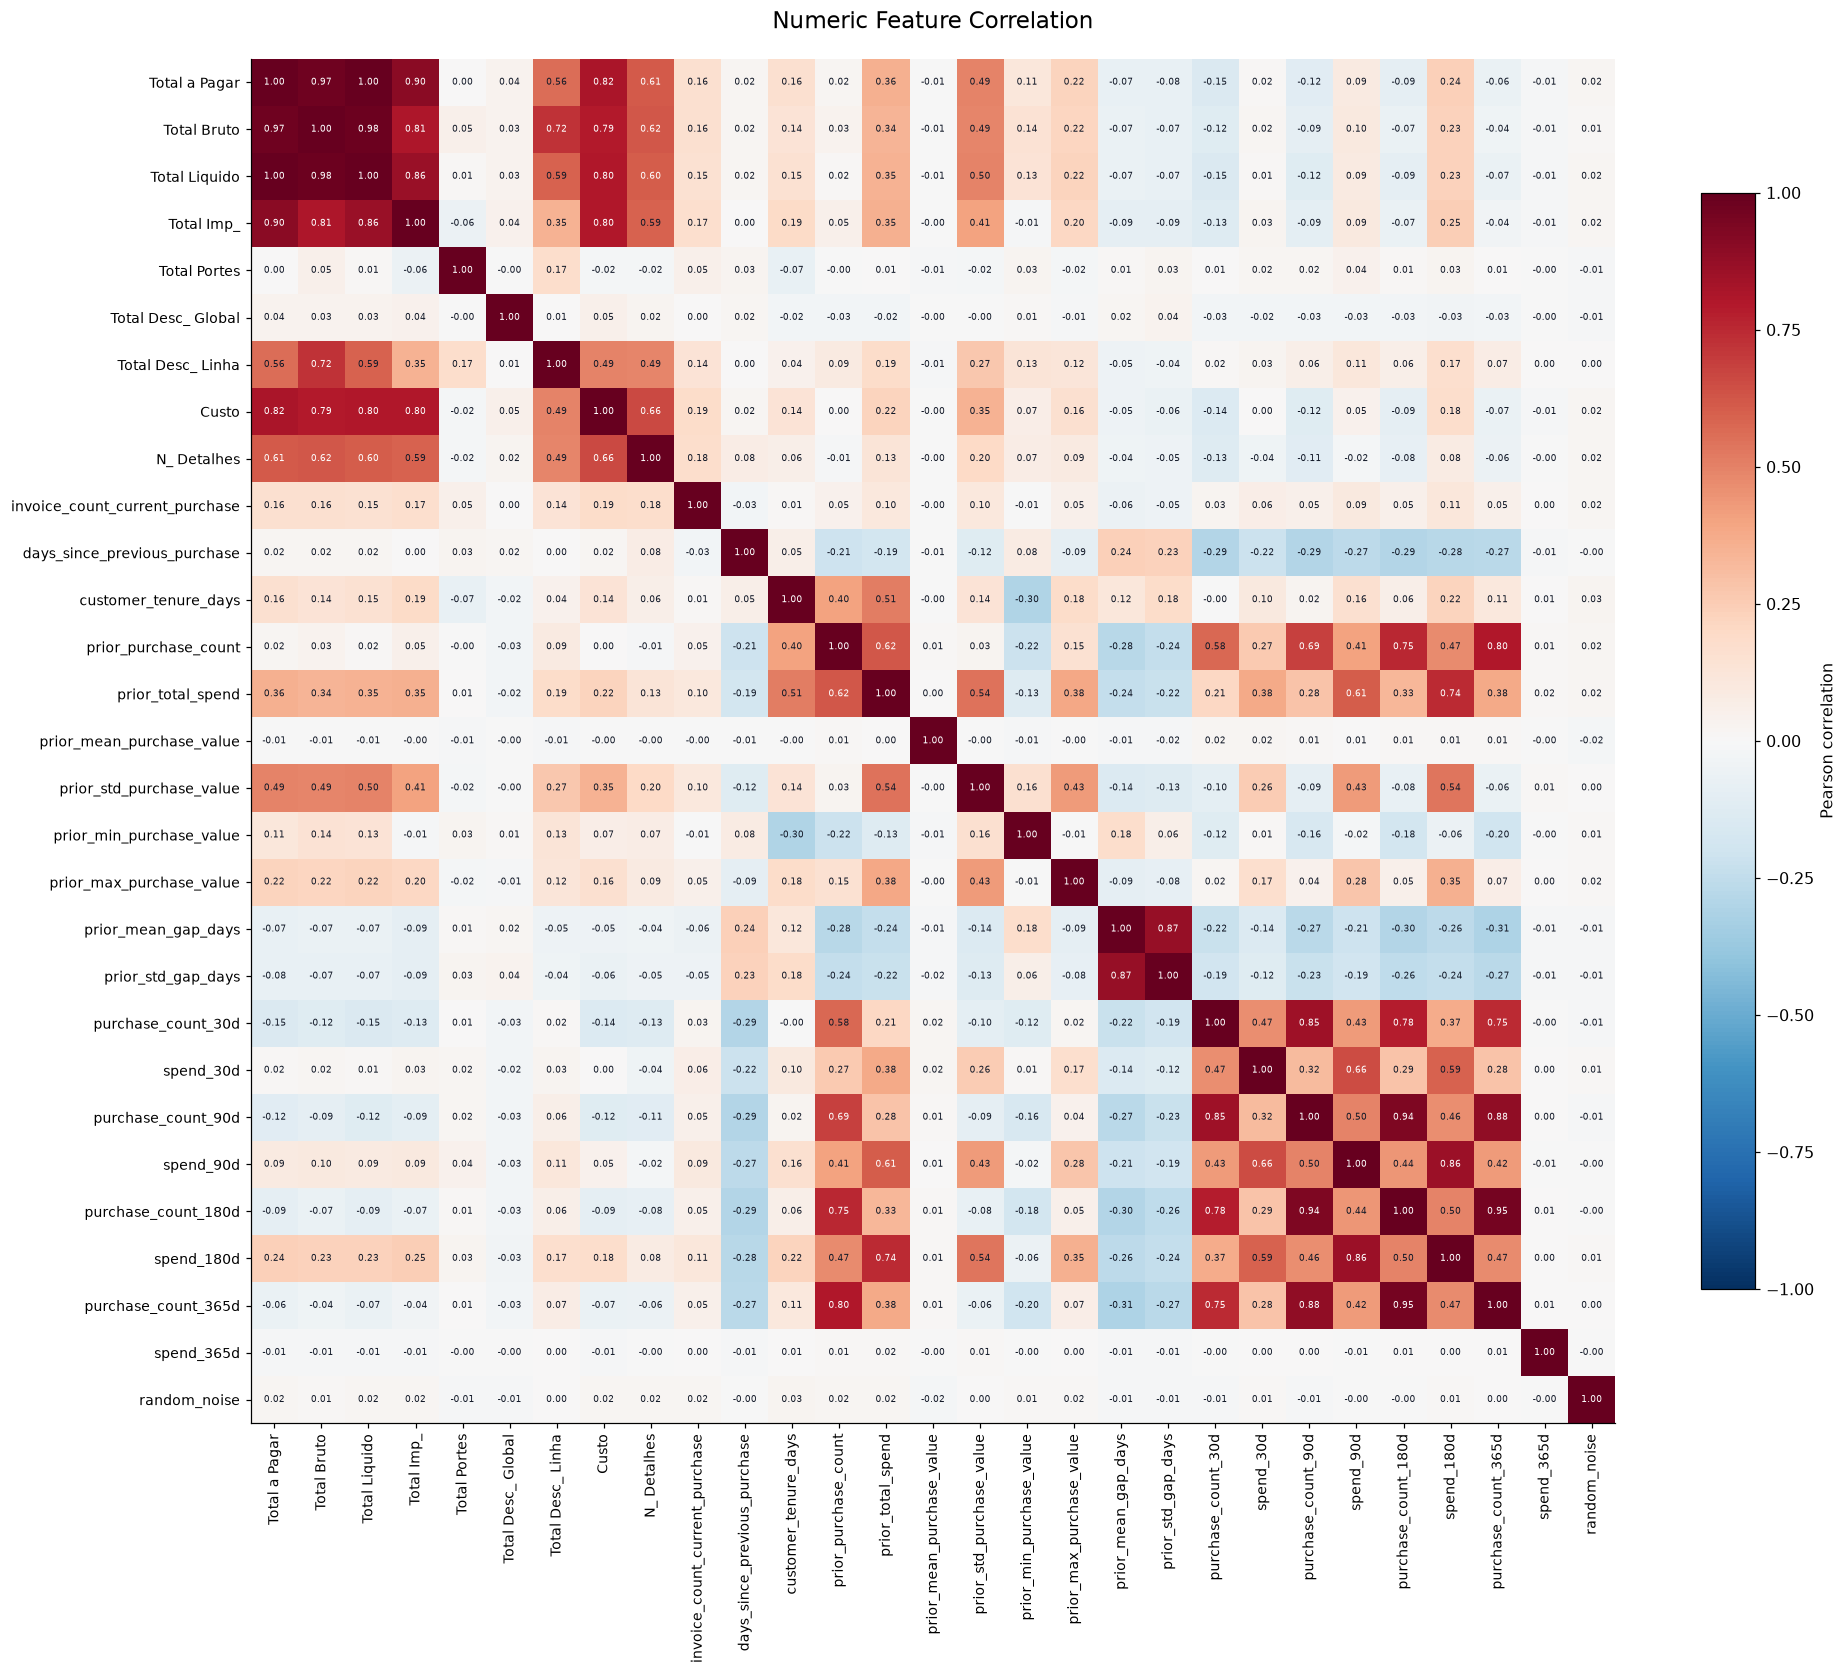

In [22]:
corr_df = train[metric_features].apply(pd.to_numeric, errors="coerce")
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(18, 15))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(metric_features)), metric_features, rotation=90, ha="center")
ax.set_yticks(range(len(metric_features)), metric_features)

for i in range(len(metric_features)):
    for j in range(len(metric_features)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color="white" if abs(v) > 0.6 else "#111827", fontsize=6)

fig.colorbar(im, ax=ax, label="Pearson correlation", shrink=0.8)
ax.set_title("Numeric Feature Correlation", fontsize=15, pad=20)

ax.tick_params(axis="both", labelsize=9)

plt.tight_layout()
plt.show()

From the correlation graph, it is possible to highlight the following strong correlations:
- `Total a Pagar` and `Total Liquido` (r ≈ 1.00).
- `Total Bruto` and `Total Liquido` (r = 0.98).
- `Total a Pagar` and `Total Bruto` (r = 0.97).
- `purchase_count_180d` and `purchase_count_365d` (r = 0.95).
- `purchase_count_90d` and `purchase_count_180d` (r = 0.94).
- `prior_mean_gap_days` and `prior_std_gap_days` (r = 0.87).
- `spend_90d` and `spend_180d` (r = 0.86).
- `purchase_count_30d` and `purchase_count_90d` (r = 0.85).

In [42]:
vif_cols = [
    "Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_",
    "Custo", "purchase_count_30d", "purchase_count_90d",
    "purchase_count_180d", "purchase_count_365d",
    "prior_mean_gap_days", "prior_std_gap_days"
]

vif_data = train[vif_cols].apply(pd.to_numeric, errors="coerce").dropna()
vif_rows = []

with warnings.catch_warnings():
    # Rank-deficient warnings indicate possible linear dependencies
    warnings.simplefilter("ignore")

    for i, col in enumerate(vif_cols):
        try:
            vif = variance_inflation_factor(vif_data.values, i)
        except Exception:
            vif = float("inf")

        vif_rows.append({
            "column": col,
            "VIF": f"{vif:,.1f}" if np.isfinite(vif) and vif < 1e6
                   else "astronomical (perfectly redundant)"
        })

vif_table = pd.DataFrame(vif_rows).sort_values("column")
vif_table

,column,VIF
4,Custo,3.6
1,Total Bruto,40.9
3,Total Imp_,astronomical (perfectly redundant)
2,Total Liquido,astronomical (perfectly redundant)
0,Total a Pagar,astronomical (perfectly redundant)
9,prior_mean_gap_days,4.7
10,prior_std_gap_days,4.3
7,purchase_count_180d,18.7
5,purchase_count_30d,3.5
8,purchase_count_365d,10.7


The VIF (Variance Inflation Factor) analysis was performed on variables that showed strong correlations in the previous heatmap, to check if they contain redundant information.
- VIF = 1: Predictor has no correlation with other variables.
- VIF < 5: Generally considered acceptable and low concern.
- VIF >5/10 : Indicates high colinearity.

Based on the outputs, we can conclude that:
- `Total a Pagar`, `Total Liquido` and `Total Imp_`: Almost perfect multicollinearity.
- `Total Bruto` (VIF = 40.92): Very high multicollinearity.
- Purchase counts (VIF = 10.72 – 18.67): High multicollinearity due to overlapping time windows.
- Purchase gap variables (VIF = 4.31–4.75): Moderate multicollinearity.
- `Custo` and `purchase_count_30d` (VIF = 3.61 and 3.50): Relatively low multicollinearity.

Therefore, it exists a substantial multicollinearity among some monetary variables and purchase frequency features, which can lead to redundancy. This will be considered during feature selection, however no variables will be removed at this stage.

## 9. Checking for outliers

In [24]:
# Check potential outliers using the IQR method
Q1 = train[metric_features].quantile(0.25)
Q3 = train[metric_features].quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (train[metric_features] < Q1 - 1.5 * IQR) |
    (train[metric_features] > Q3 + 1.5 * IQR)
)

outlier_summary = pd.DataFrame({
    "Outliers": outliers.sum(),
    "Outliers (%)": (outliers.mean() * 100).round(2)
})

display(outlier_summary.sort_values("Outliers (%)", ascending=False))

,Outliers,Outliers (%)
spend_30d,1060,16.22
Total Portes,1053,16.12
Total Desc_ Linha,822,12.58
purchase_count_180d,737,11.28
prior_min_purchase_value,671,10.27
spend_90d,661,10.12
prior_total_spend,642,9.83
Total a Pagar,592,9.06
Total Liquido,587,8.98
Total Bruto,584,8.94


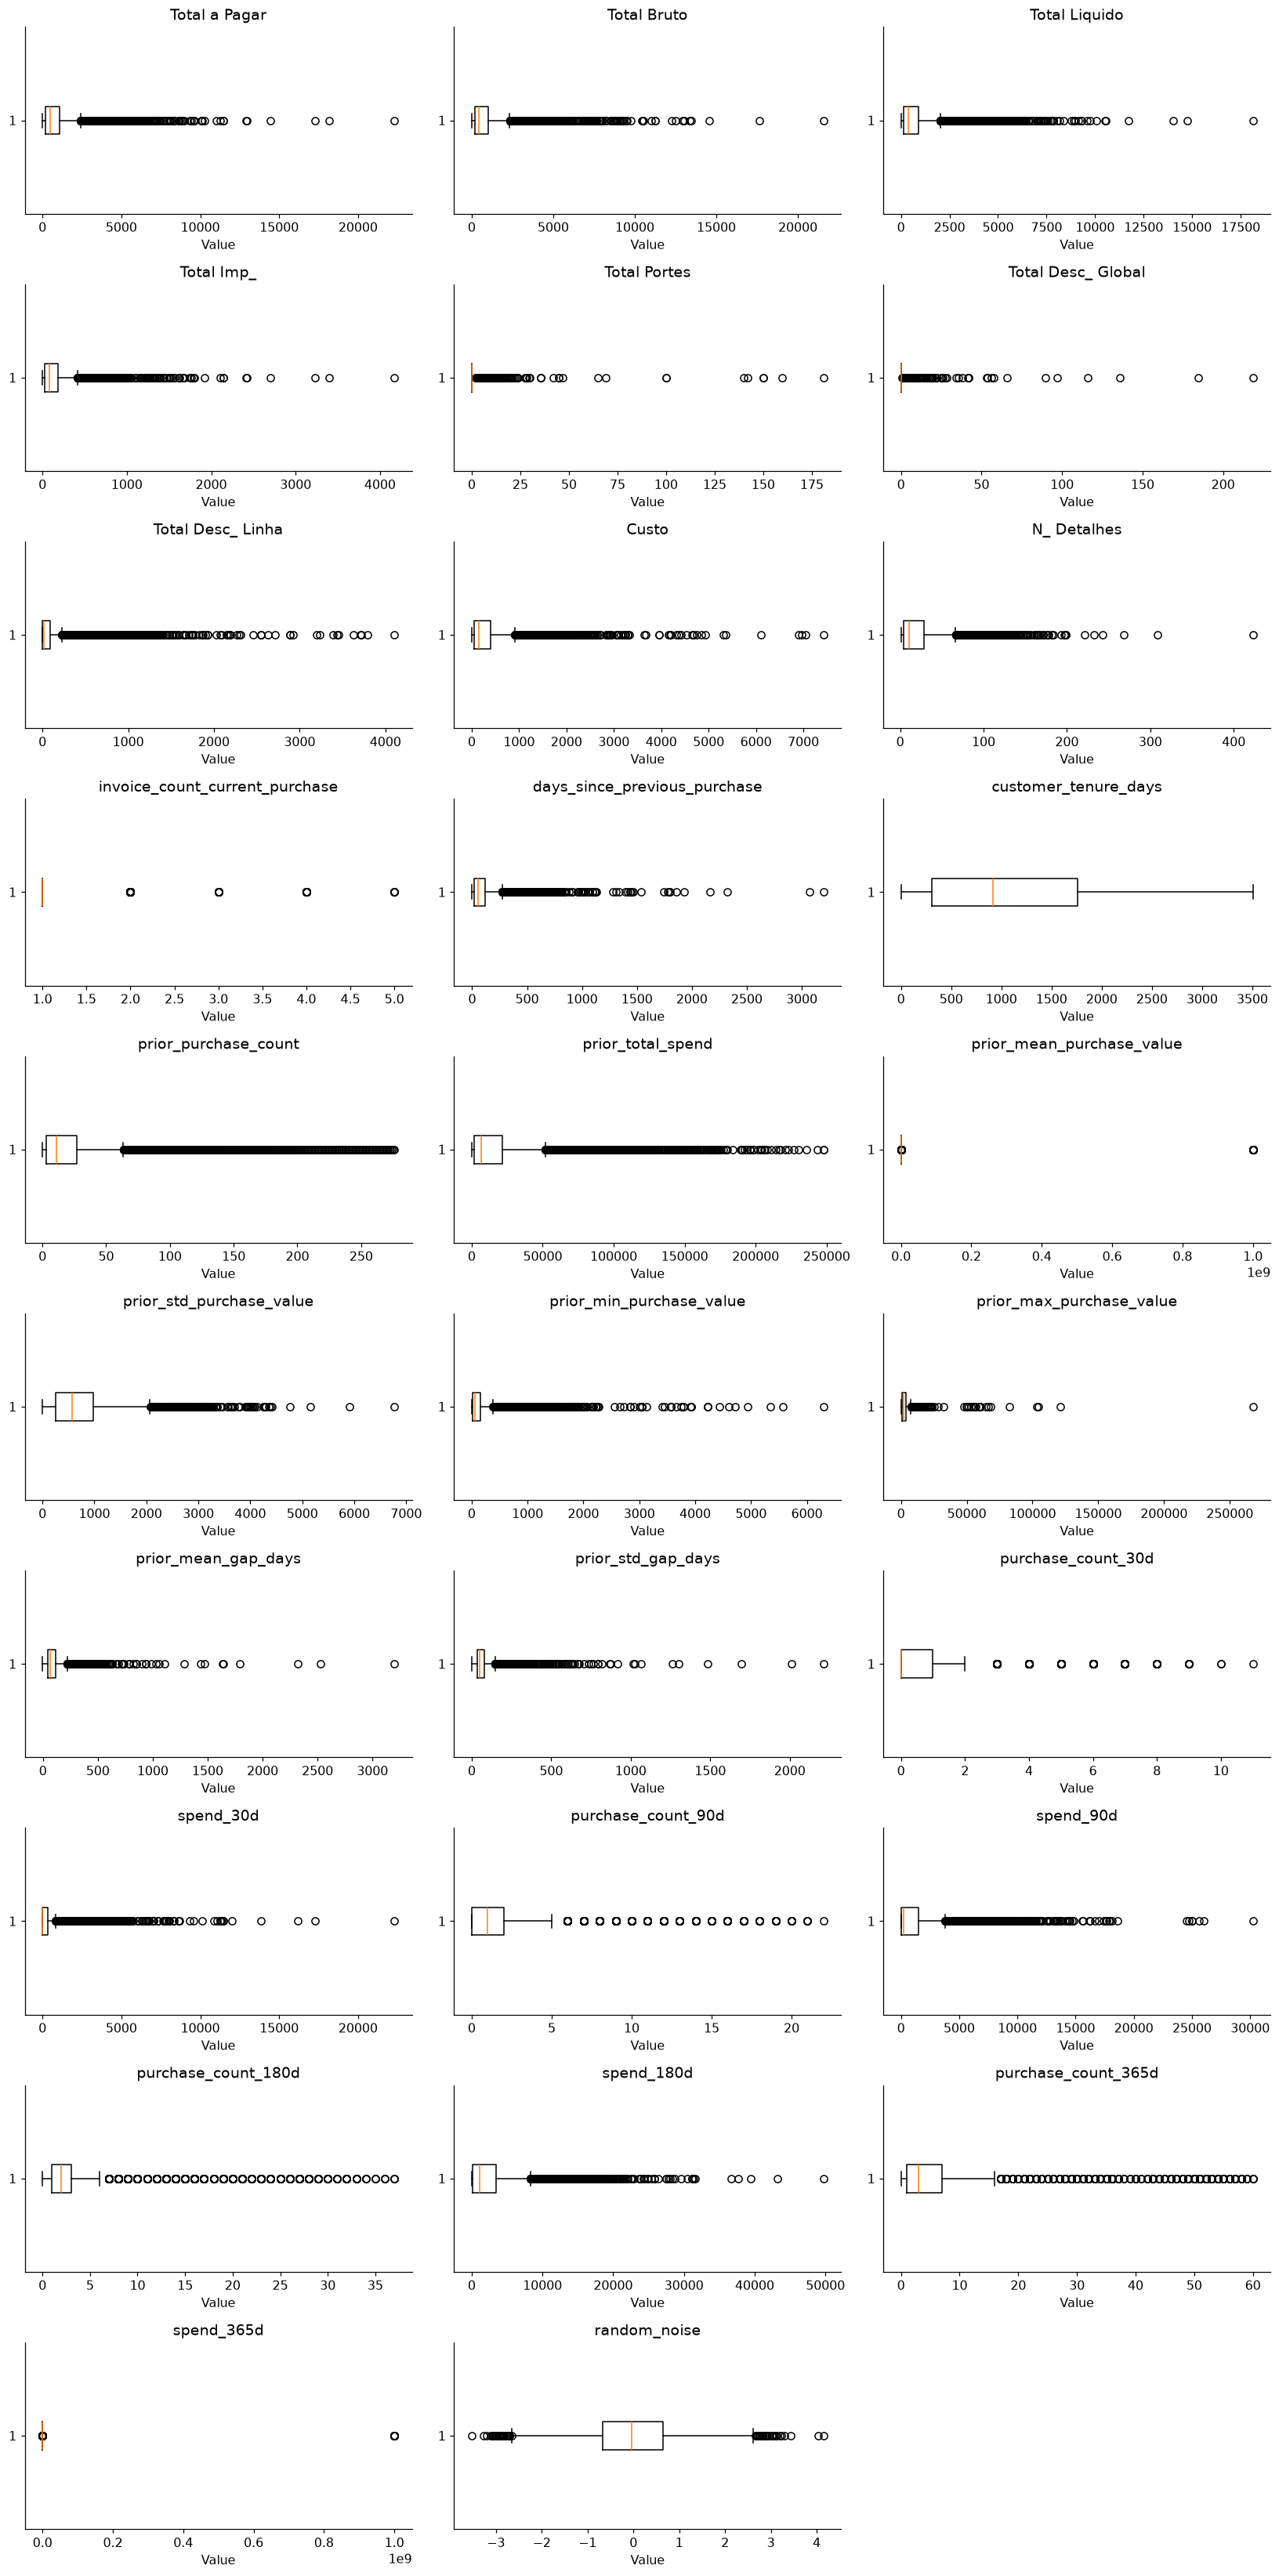

In [25]:
# Boxplots for numerical features
fig, axes = plt.subplots(10, 3, figsize=(15, 30))
axes = axes.flatten()

for i, col in enumerate(metric_features):
    axes[i].boxplot(train[col].dropna(), vert=False)
    axes[i].set_title(col)
    axes[i].set_xlabel("Value")

for j in range(len(metric_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

The dataset contains many potential outliers, particularly in spending and purchase frequency variables, particularly `spend_30d` (16.22%), `Total Portes` (16.12%) and `Total Desc_ Linha` (12.58%). However, these outliers can reflect genuine differences in customer behaviour rather than data errors. 

## 10. Summary of Data Audit

| Issue | Finding | Proposed Action |
|---|---|---|
| Data types | `purchase_date` stored as text | Convert to datetime |
| Duplicates | No duplicates found | No action needed |
| Missing values | 65 observations share missing values across 24 variables | Investigate and handle during preprocessing |
| Historical features | Missing values mainly due to limited purchase history | Apply appropriate imputation |
| Regression target | 229 returning observations have missing spending values | Exclude from regression training |
| Categorical variables | Some missing values and rare categories | Imputation and appropriate encoding |
| Invalid values | Negative purchase intervals and spending values | Investigate and correct invalid values |
| Multicollinearity | High correlations and VIF values | Evaluate feature selection |
| Outliers | Several numerical variables contain extreme values | Evaluate outlier treatment |
| `random_noise` | Weak correlations with other variables | Evaluate usefulness during feature selection |